# Final Project: Analisis Clustering Teks Postingan X (Twitter) - KRL
**Mata Kuliah:** Praktik Aplikasi Web (Kelas I2)  
**Kelompok:** 4  

---

### [PEMBAGIAN TUGAS KELOMPOK]
| No | Anggota | Bagian Tugas | Deskripsi Kontribusi & Rincian Pengerjaan |
|:---:|:---|:---:|:---|
| 1 | **Redina** | **Bagian 1 & 5** | - **Bagian 1:** Penyusunan Stopwords (Bahasa Indonesia & Inggris), kata gaul/slang media sosial, serta proteksi kata negasi agar arti sentimen teks tidak rusak.<br>- **Bagian 5:** Visualisasi Reduksi Dimensi dengan PCA 2D (Principal Component Analysis) untuk persebaran titik data cluster. |
| 2 | **Salya** | **Bagian 3 & 4** | - **Bagian 3:** Analisis Karakteristik Tiap Cluster, ekstraksi kata dominan centroid, contoh postingan representatif, dan ukuran tiap cluster.<br>- **Bagian 4:** Evaluasi Kualitas & Kejelasan Cluster (Silhouette Score) serta Uji Stabilitas Pengelompokan (Adjusted Rand Index / ARI). |
| 3 | **Alvito** | **Bagian 2 & 6** | - **Bagian 2:** Ekstraksi Fitur Teks dengan TF-IDF Vectorizer & Pemodelan K-Means Clustering (k=3).<br>- **Bagian 6:** Penamaan Tema/Label Cluster, **Word Cloud per Cluster (Sesuai Saran Dosen)**, Visualisasi Word Count Tema, dan Sanitasi Ekspor Data CSV Siap Analisis Sentimen (Bebas Error Excel). |

---

### [ALUR KERJA NOTEBOOK]
1. **Tahap Crawling Data:** Pengambilan data postingan X dengan target dinaikkan menjadi **1000 tweet**.
2. **Tahap Cleaning & Sanitasi:** Pembersihan baris rusak, newline internal, karakter asing/mojibake, serta quoting aman untuk Excel.
3. **Bagian 1 (Redina):** Stopwords & Preprocessing Teks.
4. **Bagian 2 (Alvito):** TF-IDF & K-Means Clustering.
5. **Bagian 3 (Salya):** Kata Dominan & Contoh Postingan Tiap Cluster.
6. **Bagian 4 (Salya):** Evaluasi Kualitas & Stabilitas Cluster (Silhouette & ARI).
7. **Bagian 5 (Redina):** Visualisasi PCA 2D.
8. **Bagian 6 (Alvito):** Pelabelan Tema, Word Cloud per Cluster, Word Count Tema, dan Ekspor CSV Bersih Siap Sentimen.

---
## Crawling Data X (Twitter)

In [2]:
# 1. Update paket dan instalasi dependensi sistem untuk tweet-harvest (Chromium & Node.js)
!sudo apt-get update -qq
!sudo apt-get install -y ca-certificates curl gnupg libasound2t64 libgbm1 libnss3 \
    libatk1.0-0 libatk-bridge2.0-0 libatspi2.0-0 libgtk-3-0 libx11-xcb1 libxcomposite1 \
    libxdamage1 libxfixes3 libxrandr2 libxshmfence1 libdrm2 libxkbcommon0 libxss1 libxtst6 libcups2

# 2. Setup Node.js versi 20.x LTS
!curl -fsSL https://deb.nodesource.com/setup_20.x | sudo -E bash -
!sudo apt-get install -y nodejs

# Verifikasi versi node dan tweet-harvest
!node -v
!npm -v
!npx -y tweet-harvest@latest --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'libatk1.0-0t64' instead of 'libatk1.0-0'
Note, selecting 'libatk-bridge2.0-0t64' instead of 'libatk-bridge2.0-0'
Note, selecting 'libatspi2.0-0t64' instead of 'libatspi2.0-0'
Note, selecting 'libgtk-3-0t64' instead of 'libgtk-3-0'
Note, selecting 'libcups2t64' instead of 'libcups2'
ca-certificates is already the newest version (20260601~24.04.1).
curl is already the newest version (8.5.0-2ubuntu10.15).
gnupg is already the newest version (2.4.4-2ubuntu17.6).
gnupg set to manually installed.
libasound2t64 is already the newest version (1.2.11-1ubuntu0.3).
libasound2t64 set to manually installed.
libnss3 is already the newest version (2:3.98-1ubuntu0.2).
libnss3 set to manually installed.
l

In [3]:
from getpass import getpass

# Masukkan auth_token dari akun X/Twitter Anda
# Cara ambil auth_token: Buka twitter.com -> Inspect Element (F12) -> Application -> Cookies -> 'auth_token'
twitter_auth_token = getpass('Masukkan Auth Token Akun X: ')

Masukkan Auth Token Akun X: ··········


In [4]:
# Konfigurasi Crawling 1000 Tweet
filename = 'krl_tweets_1000.csv'
search_keyword = 'KRL Bekasi since:2026-04-20 until:2026-04-30'
limit = 1000

print(f"Memulai proses crawling {limit} tweet dengan kata kunci: '{search_keyword}'...")

!npx -y tweet-harvest@latest \
    -o "{filename}" \
    -s '{search_keyword}' \
    --tab "LATEST" \
    -l {limit} \
    --token {twitter_auth_token}

Memulai proses crawling 1000 tweet dengan kata kunci: 'KRL Bekasi since:2026-04-20 until:2026-04-30'...
⠙⠹⠸⠼⠴Tweet Harvest [v2.7.1]

Research by Helmi Satria
Use it for Educational Purposes only!

This script uses Chromium Browser to crawl data from Twitter with your Twitter auth token.
Please enter your Twitter auth token when prompted.

Note: Keep your access token secret! Don't share it with anyone else.
Note: This script only runs on your local device.


Opening twitter search page...


-- Scrolling... (1) (2)
Filling in keywords: KRL Bekasi since:2026-04-20 until:2026-04-30

 (3) (4) (5)Created new directory: /content/tweets-data


Your tweets saved to: /content/tweets-data/krl_tweets_1000.csv
Total tweets saved: 20

-- Scrolling... (1) (2) (3) (4)

Your tweets saved to: /content/tweets-data/krl_tweets_1000.csv
Total tweets saved: 40

-- Scrolling... (1)

Your tweets saved to: /content/tweets-data/krl_tweets_1000.csv
Total tweets saved: 60

-- Scrolling... (1) (2)

Your tweets sav

---
## Penggabungan & Pembersihan Data Mentah

In [5]:
import os
import pandas as pd
import numpy as np

# Daftar file potensial yang dibaca (file 1000 crawling baru maupun file lama)
daftar_file = ['krl_tweets_1000.csv', 'krl.csv', 'krl2.csv', 'dataset_krl_bersih.csv']
list_df = []

for f in daftar_file:
    if os.path.exists(f):
        try:
            df_baca = pd.read_csv(f, on_bad_lines='skip', lineterminator='\n', encoding='utf-8')
            list_df.append(df_baca)
            print(f"Berhasil memuat file: {f} (Jumlah: {len(df_baca)} baris)")
        except Exception as err:
            print(f"File {f} dilewati: {err}")

# Jika file belum ada di Colab, beri opsi upload manual
if len(list_df) == 0:
    print("File CSV hasil crawling belum ditemukan di folder. Silakan upload file CSV:")
    try:
        from google.colab import files
        uploaded = files.upload()
        for nama_file in uploaded.keys():
            df_upload = pd.read_csv(nama_file, on_bad_lines='skip', lineterminator='\n', encoding='utf-8')
            list_df.append(df_upload)
            print(f"Berhasil upload & baca: {nama_file} ({len(df_upload)} baris)")
    except Exception as e:
        print("Upload tidak tersedia:", e)

if len(list_df) > 0:
    df_raw = pd.concat(list_df, ignore_index=True)
    print(f"\nTotal data mentah tergabung: {len(df_raw)} baris")
else:
    raise FileNotFoundError("Tidak ada data CSV yang tersedia untuk diproses.")

# Deteksi nama kolom teks
kolom_teks = 'full_text' if 'full_text' in df_raw.columns else ('text' if 'text' in df_raw.columns else df_raw.columns[0])
print(f"Kolom teks yang digunakan: '{kolom_teks}'")

File CSV hasil crawling belum ditemukan di folder. Silakan upload file CSV:


Saving krl_tweets_1000.csv to krl_tweets_1000.csv
Berhasil upload & baca: krl_tweets_1000.csv (860 baris)

Total data mentah tergabung: 860 baris
Kolom teks yang digunakan: 'full_text'


In [6]:
import re
import html

def sanitize_csv_text(text):
    """
    Sanitasi teks tweet agar tidak merusak struktur tabel CSV / Excel:
    - Menghilangkan enter/newline (\n, \r) agar 1 tweet tetap 1 baris utuh
    - Mengganti tanda kutip ganda internal menjadi kutip tunggal
    - Menghapus karakter kontrol non-printable
    - Menghapus aksara asing/mojibake yang rusak
    """
    if not isinstance(text, str):
        return ""
    text = html.unescape(text)
    # Hapus enter dan tab
    text = text.replace('\r\n', ' ').replace('\n', ' ').replace('\r', ' ').replace('\t', ' ')
    # Ganti kutip ganda internal dengan kutip tunggal
    text = text.replace('"', "'")
    # Hanya ambil karakter printable
    text = "".join(ch for ch in text if ch.isprintable())
    # Bersihkan simbol aksara non-latin/mojibake
    text = re.sub(r'[^\x00-\x7F\u00C0-\u024F]+', ' ', text)
    # Rapikan spasi
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def clean_for_nlp(text):
    """
    Pembersihan teks untuk analisis NLP (TF-IDF & Clustering):
    - Lowercase
    - Hapus URL, Mention (@), Hashtag (#)
    - Hapus angka & tanda baca
    - Hanya pertahankan huruf alfabet latin dan spasi
    """
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)   # Hapus URL
    text = re.sub(r'@\w+', ' ', text)                     # Hapus Mention (@user)
    text = re.sub(r'#\w+', ' ', text)                     # Hapus Hashtag (#topik)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)            # Hapus karakter non-ASCII
    text = re.sub(r'\d+', ' ', text)                      # Hapus angka
    text = re.sub(r'[^a-z\s]', ' ', text)                 # Hanya huruf a-z dan spasi
    text = re.sub(r'\s+', ' ', text).strip()              # Hapus spasi berlebih
    return text

# Terapkan pembersihan
df = df_raw.copy()
df['full_text'] = df[kolom_teks].apply(sanitize_csv_text)
df['clean_text'] = df['full_text'].apply(clean_for_nlp)

# Filter hanya bahasa Indonesia (jika ada kolom 'lang')
if 'lang' in df.columns:
    df = df[df['lang'].isin(['in', 'id']) | df['lang'].isna()]

# Hapus baris yang kosong atau hanya karakter pendek (< 4 huruf)
df = df.dropna(subset=['full_text', 'clean_text'])
df = df[df['clean_text'].str.strip().str.len() > 3]

# Hapus duplikasi berdasarkan clean_text
df = df.drop_duplicates(subset=['clean_text'])
df = df.reset_index(drop=True)

print(f"Total data bersih siap clustering & analisis: {len(df)} baris")
df[['full_text', 'clean_text']].head(5)

Total data bersih siap clustering & analisis: 829 baris


,full_text,clean_text
0,91 relawan PMI mendapat apresiasi langsung dar...,relawan pmi mendapat apresiasi langsung dari j...
1,"@drhaltekehalte @romagandum mau tidur nangis, ...",mau tidur nangis bangun tidur nangis tiap liat...
2,@TaufiqSobari 3 hari yang lalu ada buruh perem...,hari yang lalu ada buruh perempuan yg gugur di...
3,Duka di Stasiun Bekasi Timur: 16 Korban Kecela...,duka di stasiun bekasi timur korban kecelakaan...
4,Sebanyak 91 relawan PMI mendapat bonus usai me...,sebanyak relawan pmi mendapat bonus usai memba...


---
## Stopword & Preprocessing Teks

In [7]:
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords as nltk_stopwords

# Kata negasi yang WAJIB dipertahankan agar makna sentimen tetap akurat
NEGASI = {
    'tidak', 'bukan', 'belum', 'jangan', 'tanpa',
    'gak', 'ga', 'ngga', 'engga', 'enggak',
    'nggak', 'tak', 'ndak'
}

# 1. Stopword umum Bahasa Indonesia dan Bahasa Inggris
stopwords = set(nltk_stopwords.words('indonesian'))
stopwords.update(nltk_stopwords.words('english'))

# 2. Kata percakapan umum media sosial / slang yang kurang informatif
stopwords.update([
    'ya', 'ye', 'yuk', 'dah', 'yey',
    'nih', 'sih', 'dong', 'deh', 'kok',
    'lah', 'lho', 'loh', 'tuh', 'kan',
    'wkwk', 'wkwkwk', 'hehe', 'haha',
    'yg', 'dgn', 'kalo', 'utk', 'tp', 'bgt', 'dr', 'aja', 'nya'
])

# 3. Kata tambahan pelengkap media/berita
stopwords.update([
    'baca', 'selengkapnya', 'simak',
    'berikut', 'tersebut', 'yakni',
    'adapun', 'ujar', 'ungkap', 'tutur',
    'https', 'co', 'di', 'ke', 'dari', 'krl', 'commuter', 'line'
])

# 4. Hapus kata negasi dari daftar stopword (jangan sampai terhapus)
stopwords.difference_update(NEGASI)

# Konversi ke list terurut untuk TfidfVectorizer
stopwords_list = sorted(stopwords)

print(f"Jumlah total stopword: {len(stopwords_list)}")
print(f"Kata negasi yang dilindungi ({len(NEGASI)} kata):", sorted(NEGASI))
print("Contoh 20 stopword terdaftar:", stopwords_list[:20])

Jumlah total stopword: 980
Kata negasi yang dilindungi (13 kata): ['belum', 'bukan', 'engga', 'enggak', 'ga', 'gak', 'jangan', 'ndak', 'ngga', 'nggak', 'tak', 'tanpa', 'tidak']
Contoh 20 stopword terdaftar: ['a', 'about', 'above', 'ada', 'adalah', 'adanya', 'adapun', 'after', 'again', 'against', 'agak', 'agaknya', 'agar', 'ain', 'aja', 'akan', 'akankah', 'akhir', 'akhiri', 'akhirnya']


---
## 2. TF-IDF Vectorization & Pemodelan K-Means

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
import numpy as np

# Ekstraksi Fitur Teks dengan TF-IDF
vectorizer = TfidfVectorizer(
    stop_words=stopwords_list,
    max_df=0.4,   # Abaikan kata yang muncul di lebih dari 40% dokumen (terlalu umum)
    min_df=2      # Abaikan kata yang hanya muncul di kurang dari 2 dokumen
)
X = vectorizer.fit_transform(df['clean_text'])
print(f"Ukuran Matriks TF-IDF: {X.shape} (Baris Dokumen: {X.shape[0]}, Fitur Kata: {X.shape[1]})")

# Pemodelan K-Means (3 Cluster)
true_k = 3
model = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=10, random_state=42)
model.fit(X)

# Mengurutkan nomor cluster berdasarkan jumlah anggota terbanyak ke terdikit (0: terbesar, 2: terkecil)
urutan = np.argsort(-np.bincount(model.labels_))
peta = {lama: baru for baru, lama in enumerate(urutan)}
df['cluster'] = [peta[l] for l in model.labels_]
pusat = model.cluster_centers_[urutan]

print("\nDistribusi Jumlah Postingan Tiap Cluster:")
distribusi = df['cluster'].value_counts().sort_index()
for cl, jml in distribusi.items():
    print(f"  - Cluster {cl}: {jml} tweet ({jml/len(df)*100:.2f}%)")

Ukuran Matriks TF-IDF: (829, 1297) (Baris Dokumen: 829, Fitur Kata: 1297)

Distribusi Jumlah Postingan Tiap Cluster:
  - Cluster 0: 502 tweet (60.55%)
  - Cluster 1: 272 tweet (32.81%)
  - Cluster 2: 55 tweet (6.63%)


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['baiknya', 'berkali', 'kali', 'kurangnya', 'mata', 'olah', 'sekurang', 'setidak', 'tama', 'tidaknya'] not in stop_words.
  warnings.warn(


---
## 3. Kata Dominan, Contoh Postingan & Ukuran Cluster

In [9]:
terms = vectorizer.get_feature_names_out()
order_centroids = pusat.argsort()[:, ::-1]

for i in range(true_k):
    idx = df.index[df['cluster'] == i]
    print("=" * 65)
    print(f"CLUSTER {i} | Jumlah Postingan: {len(idx)} ({len(idx)/len(df)*100:.1f}%)")
    print("=" * 65)
    print("Kata Dominan (Top 10):", ", ".join(terms[j] for j in order_centroids[i, :10]))
    print("\nContoh Postingan Paling Representatif:")

    # Hitung kedekatan tweet terhadap centroid
    kemiripan = np.asarray(X[idx].dot(pusat[i])).ravel()
    terdekat = idx[np.argsort(-kemiripan)[:3]]
    for n, t in enumerate(df.loc[terdekat, 'full_text'], 1):
        print(f"  {n}. {t[:220]}...")
    print()

CLUSTER 0 | Jumlah Postingan: 502 (60.6%)
Kata Dominan (Top 10): kereta, taksi, cikarang, anggrek, sm, api, tabrakan, insiden, green, perlintasan

Contoh Postingan Paling Representatif:
  1. Sejumlah penumpang membatalkan perjalanan kereta api pasca adanya insiden tabrakan kereta Api Argo Bromo Anggrek dan Kereta Listrik (KRL) di Bekasi Timur. Kereta | Bekasi Timur | Innalillahi | KRL Commuter Line | KA Argo...
  2. Insiden kecelakaan kereta api terjadi di kawasan Bekasi Timur, Jawa Barat, pada Senin (27/4) malam, sekitar pukul 20.50 WIB. Peristiwa ini melibatkan kereta api (KA) jarak jauh Argo Bromo Anggrek dan KRL Commuter Line di...
  3. Kereta Jarak Jauh Argo Bromo Anggrek menabrak KRL di Stasiun Bekasi Timur, Senin (27/4) sekitar pukul 20.52 WIB. Kecelakaan bermula saat KRL Cikarang-Angke menuju Jakarta menabrak taksi Green SM. Tabrakan membuat perjala...

CLUSTER 1 | Jumlah Postingan: 272 (32.8%)
Kata Dominan (Top 10): korban, meninggal, anggrek, keluarga, luka, orang, semoga, ke

---
## 4. Evaluasi Kualitas & Stabilitas Cluster

In [10]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Menghitung Silhouette Score
sil = silhouette_score(X, df['cluster'])
print(f"Silhouette Score (k=3): {sil:.4f}")

# 2. Uji Stabilitas Pengelompokan (Adjusted Rand Index)
dasar = model.labels_
print("\nUji Stabilitas Clustering (Adjusted Rand Index terhadap berbagai random_state):")
for seed in [1, 7, 123]:
    m2 = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=10, random_state=seed).fit(X)
    ari = adjusted_rand_score(dasar, m2.labels_)
    print(f"  - ARI random_state=42 vs {seed}: {ari:.3f}")

Silhouette Score (k=3): 0.0148

Uji Stabilitas Clustering (Adjusted Rand Index terhadap berbagai random_state):
  - ARI random_state=42 vs 1: 0.934
  - ARI random_state=42 vs 7: 0.818
  - ARI random_state=42 vs 123: 0.929


---
## 5. Visualisasi Cluster PCA 2 Dimensi

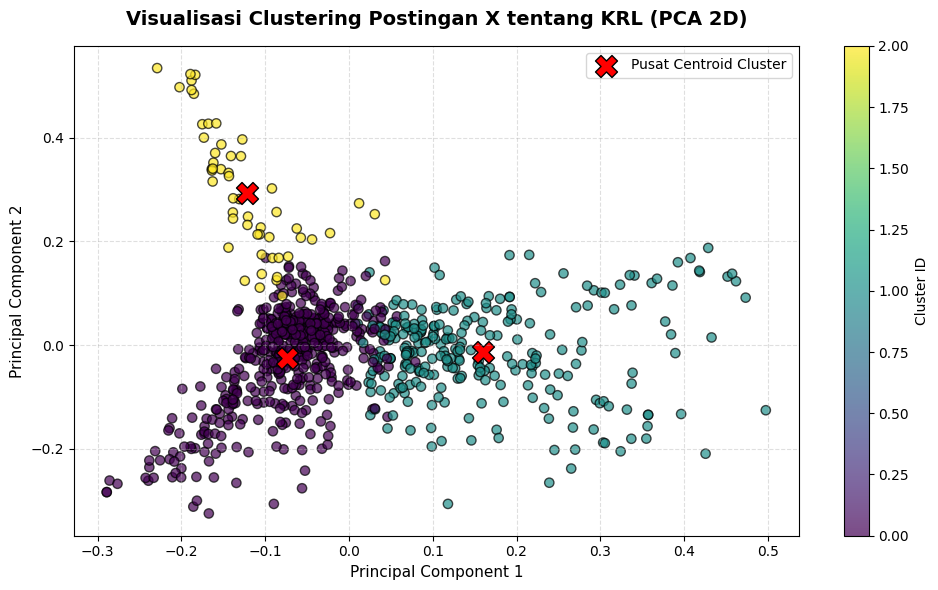

In [11]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduksi dimensi dengan PCA
pca = PCA(n_components=2, random_state=0)
titik = pca.fit_transform(X.toarray())
titik_pusat = pca.transform(pusat)

# Plot scatter PCA
plt.figure(figsize=(10, 6))
scatter = plt.scatter(titik[:, 0], titik[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7, edgecolors='k', s=45)
plt.scatter(titik_pusat[:, 0], titik_pusat[:, 1], marker='X', s=250, c='red', label='Pusat Centroid Cluster', edgecolors='black')

plt.title('Visualisasi Clustering Postingan X tentang KRL (PCA 2D)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Principal Component 1', fontsize=11)
plt.ylabel('Principal Component 2', fontsize=11)
plt.legend(loc='upper right')
plt.colorbar(scatter, label='Cluster ID')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

---
## 6. Penamaan Tema, Word Cloud per Cluster, Word Count & Ekspor Data

In [12]:
TEMA = {
    0: 'Respons Kebijakan & Informasi Operasional KRL',
    1: 'Keterlambatan, Gangguan Jalur & Keluhan Penumpang',
    2: 'Insiden, Evakuasi & Dampak Perjalanan Stasiun'
}

df['tema_cluster'] = df['cluster'].map(TEMA)

# Ringkasan hasil clustering
ringkasan = (
    df.groupby(['cluster', 'tema_cluster'])
      .size()
      .reset_index(name='jumlah_postingan')
)
ringkasan['persen'] = (ringkasan['jumlah_postingan'] / len(df) * 100).round(2)
ringkasan['lima_kata_dominan'] = [
    ', '.join(terms[j] for j in order_centroids[i, :5]) for i in ringkasan['cluster']
]

display(ringkasan)

,cluster,tema_cluster,jumlah_postingan,persen,lima_kata_dominan
0,0,Respons Kebijakan & Informasi Operasional KRL,502,60.55,"kereta, taksi, cikarang, anggrek, sm"
1,1,"Keterlambatan, Gangguan Jalur & Keluhan Penumpang",272,32.81,"korban, meninggal, anggrek, keluarga, luka"
2,2,"Insiden, Evakuasi & Dampak Perjalanan Stasiun",55,6.63,"gerbong, wanita, perempuan, menteri, khusus"


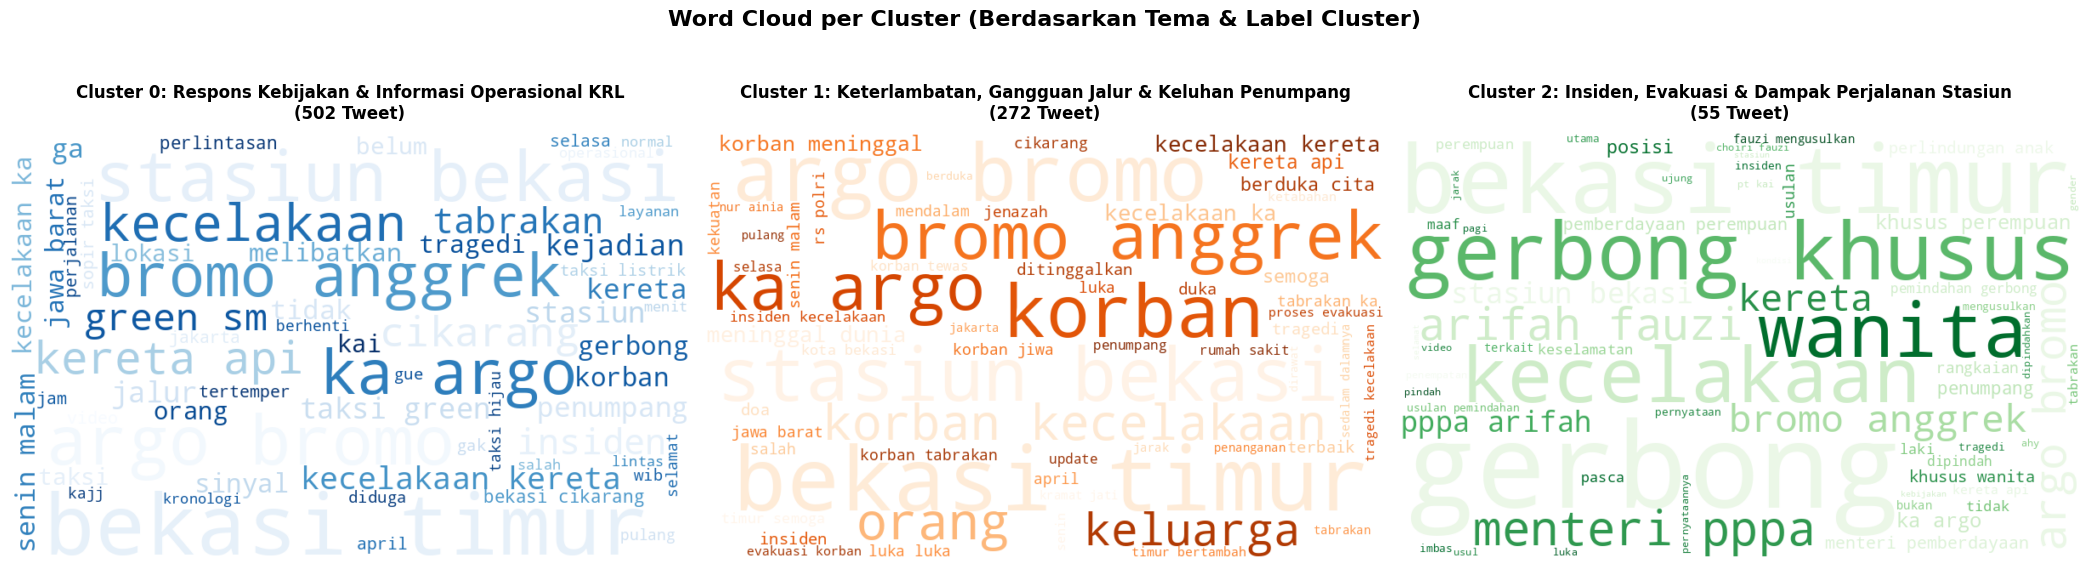

In [13]:
from wordcloud import WordCloud

# Visualisasi Word Cloud per Cluster (Saran Dosen)
fig, axes = plt.subplots(1, true_k, figsize=(21, 6))
colormaps = ['Blues', 'Oranges', 'Greens']

for i in range(true_k):
    # Gabungkan teks khusus untuk cluster i
    teks_cluster = ' '.join(df[df['cluster'] == i]['clean_text'])

    wc = WordCloud(
        stopwords=stopwords,
        background_color='white',
        colormap=colormaps[i % len(colormaps)],
        max_words=60,
        width=800,
        height=500,
        random_state=42
    ).generate(teks_cluster)

    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(f"Cluster {i}: {TEMA.get(i, '')}\n({(df['cluster']==i).sum()} Tweet)", fontsize=12, fontweight='bold', pad=10)
    axes[i].axis('off')

plt.suptitle("Word Cloud per Cluster (Berdasarkan Tema & Label Cluster)", fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

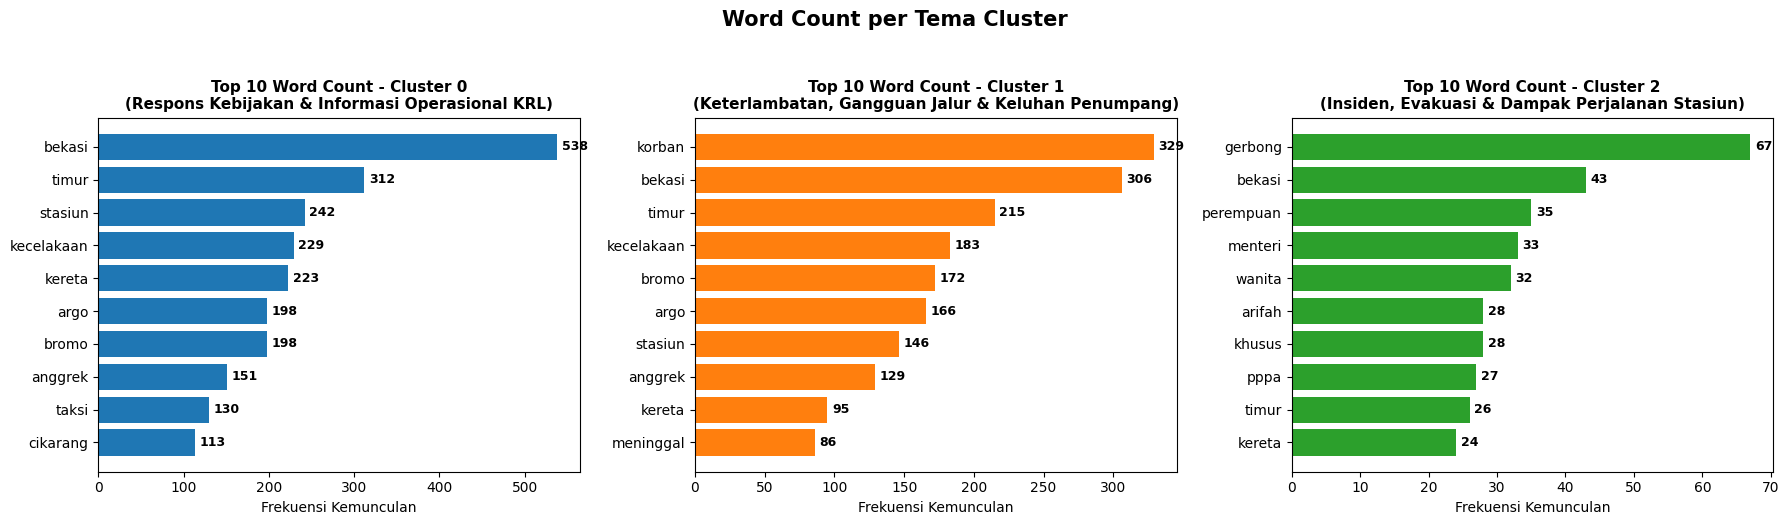

In [14]:
from collections import Counter

# Visualisasi Bar Chart Frekuensi Kata (Word Count) untuk Setiap Tema Cluster
fig, axes = plt.subplots(1, true_k, figsize=(18, 5))

for i in range(true_k):
    kata_cluster = ' '.join(df[df['cluster'] == i]['clean_text']).split()
    # Filter stopwords dan kata pendek
    kata_terfilter = [k for k in kata_cluster if k not in stopwords and len(k) > 2]
    top_10 = Counter(kata_terfilter).most_common(10)

    if top_10:
        kata_list, hitung_list = zip(*top_10)
    else:
        kata_list, hitung_list = [], []

    ax = axes[i]
    bars = ax.barh(kata_list[::-1], hitung_list[::-1], color=plt.cm.tab10(i))
    ax.set_title(f"Top 10 Word Count - Cluster {i}\n({TEMA.get(i, '')})", fontsize=11, fontweight='bold')
    ax.set_xlabel('Frekuensi Kemunculan')

    # Tampilkan angka frekuensi
    for bar in bars:
        w = bar.get_width()
        ax.text(w + max(hitung_list)*0.01 if hitung_list else 1, bar.get_y() + bar.get_height()/2,
                f'{int(w)}', va='center', ha='left', fontsize=9, fontweight='bold')

plt.suptitle("Word Count per Tema Cluster", fontsize=15, fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

### Ekspor Dataset Bersih Siap Analisis Sentimen

In [15]:
import csv

# 1. Ekspor dataset utama yang sudah bersih dan terlabeli cluster
file_utama = 'hasil_clustering_krl_clean_1000.csv'
df.to_csv(
    file_utama,
    index=False,
    encoding='utf-8-sig',
    quoting=csv.QUOTE_ALL,
    lineterminator='\r\n'
)

# 2. Ekspor tabel ringkasan tema cluster
file_ringkasan = 'ringkasan_cluster_krl.csv'
ringkasan.to_csv(
    file_ringkasan,
    index=False,
    encoding='utf-8-sig',
    quoting=csv.QUOTE_ALL,
    lineterminator='\r\n'
)

print("=" * 60)
print("EKSPOR BERHASIL!")
print(f"1. File Dataset Utama : '{file_utama}' ({len(df)} baris data)")
print(f"2. File Ringkasan     : '{file_ringkasan}'")
print("=" * 60)

# Download otomatis jika dijalankan di Google Colab
try:
    from google.colab import files
    files.download(file_utama)
    files.download(file_ringkasan)
    print("Memicu unduhan otomatis ke komputer...")
except Exception:
    print("Dijalankan di lingkungan lokal, file tersimpan di folder kerja.")

EKSPOR BERHASIL!
1. File Dataset Utama : 'hasil_clustering_krl_clean_1000.csv' (829 baris data)
2. File Ringkasan     : 'ringkasan_cluster_krl.csv'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Memicu unduhan otomatis ke komputer...


In [16]:
# Verifikasi Integritas File CSV Hasil Ekspor
df_cek = pd.read_csv(file_utama, encoding='utf-8-sig')

print("=== VERIFIKASI INTEGRITAS FILE CSV ===")
print(f"Total baris asli               : {len(df)}")
print(f"Total baris terbaca di CSV     : {len(df_cek)}")
print(f"Baris kosong pada teks bersih  : {df_cek['clean_text'].isna().sum()}")
print("Status Konsistensi Data        :", "LULUS (100% Cocok & Rapi)" if len(df) == len(df_cek) else "GAGAL")

print("\nPratinjau 5 Baris Data Siap Analisis Sentimen:")
display(df_cek[['full_text', 'clean_text', 'cluster', 'tema_cluster']].head())

=== VERIFIKASI INTEGRITAS FILE CSV ===
Total baris asli               : 829
Total baris terbaca di CSV     : 829
Baris kosong pada teks bersih  : 0
Status Konsistensi Data        : LULUS (100% Cocok & Rapi)

Pratinjau 5 Baris Data Siap Analisis Sentimen:


,full_text,clean_text,cluster,tema_cluster
0,91 relawan PMI mendapat apresiasi langsung dar...,relawan pmi mendapat apresiasi langsung dari j...,0,Respons Kebijakan & Informasi Operasional KRL
1,"@drhaltekehalte @romagandum mau tidur nangis, ...",mau tidur nangis bangun tidur nangis tiap liat...,0,Respons Kebijakan & Informasi Operasional KRL
2,@TaufiqSobari 3 hari yang lalu ada buruh perem...,hari yang lalu ada buruh perempuan yg gugur di...,0,Respons Kebijakan & Informasi Operasional KRL
3,Duka di Stasiun Bekasi Timur: 16 Korban Kecela...,duka di stasiun bekasi timur korban kecelakaan...,1,"Keterlambatan, Gangguan Jalur & Keluhan Penumpang"
4,Sebanyak 91 relawan PMI mendapat bonus usai me...,sebanyak relawan pmi mendapat bonus usai memba...,0,Respons Kebijakan & Informasi Operasional KRL


---
## Regresi Linier

In [37]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [38]:
from google.colab import files
files.upload()

Saving hasil_clustering_krl_clean_1000.csv to hasil_clustering_krl_clean_1000 (1).csv


{'hasil_clustering_krl_clean_1000 (1).csv': b'\xef\xbb\xbf"conversation_id_str","created_at","favorite_count","full_text","id_str","image_url","in_reply_to_screen_name","lang","location","quote_count","reply_count","retweet_count","tweet_url","user_id_str","username\r","clean_text","cluster","tema_cluster"\r\n"2050102168469016695","2026-05-01T06:37:00.000Z","5","91 relawan PMI mendapat apresiasi langsung dari Jusuf Kalla usai sigap membantu evakuasi korban kecelakaan KRL di Bekasi Timur. Aksi cepat, kerja kemanusiaan, dan solidaritas nyata di lapangan jadi bukti bahwa relawan selalu hadir saat dibutuhkan. #JuruDamai #JusufKalla https://t.co/s7qE49xlyp","2050102168469016695","https://pbs.twimg.com/media/HHNtDrjbEAAgwnR.jpg","","in","","0","1","4","https://x.com/Chintya___99/status/2050102168469016695","1214218873651650561","Chintya___99\r","relawan pmi mendapat apresiasi langsung dari jusuf kalla usai sigap membantu evakuasi korban kecelakaan krl di bekasi timur aksi cepat kerja kemanus

In [39]:
nama_file = 'hasil_clustering_krl_clean_1000.csv'   # ganti bila nama berkas berbeda
raw = pd.read_csv(nama_file)

print('Jumlah baris:', len(raw))
print('Kolom:', raw.columns.tolist())
raw.head()

Jumlah baris: 829
Kolom: ['conversation_id_str', 'created_at', 'favorite_count', 'full_text', 'id_str', 'image_url', 'in_reply_to_screen_name', 'lang', 'location', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'user_id_str', 'username\r', 'clean_text', 'cluster', 'tema_cluster']


,conversation_id_str,created_at,favorite_count,full_text,id_str,image_url,in_reply_to_screen_name,lang,location,quote_count,reply_count,retweet_count,tweet_url,user_id_str,username\r,clean_text,cluster,tema_cluster
0,2050102168469016695,2026-05-01T06:37:00.000Z,5,91 relawan PMI mendapat apresiasi langsung dar...,2050102168469016695,https://pbs.twimg.com/media/HHNtDrjbEAAgwnR.jpg,NaN,in,NaN,0,1,4,https://x.com/Chintya___99/status/205010216846...,1214218873651650561,Chintya___99\r,relawan pmi mendapat apresiasi langsung dari j...,0,Respons Kebijakan & Informasi Operasional KRL
1,2049773337292005535,2026-05-01T06:29:32.000Z,2,"@drhaltekehalte @romagandum mau tidur nangis, ...",2050100286925246650,NaN,drhaltekehalte,id,NaN,0,1,0,https://x.com/dunkiiindunme/status/20501002869...,1151396258692468737,dunkiiindunme\r,mau tidur nangis bangun tidur nangis tiap liat...,0,Respons Kebijakan & Informasi Operasional KRL
2,2049829022407020905,2026-05-01T06:22:20.000Z,3,@TaufiqSobari 3 hari yang lalu ada buruh perem...,2050098477028512122,NaN,TaufiqSobari,id,NaN,0,0,3,https://x.com/BoeroehI98505/status/20500984770...,1955200057109778435,BoeroehI98505\r,hari yang lalu ada buruh perempuan yg gugur di...,0,Respons Kebijakan & Informasi Operasional KRL
3,2050095447776321606,2026-05-01T06:10:18.000Z,0,Duka di Stasiun Bekasi Timur: 16 Korban Kecela...,2050095447776321606,NaN,NaN,id,NaN,0,0,0,https://x.com/liputan6dotcom/status/2050095447...,47596019,liputan6dotcom\r,duka di stasiun bekasi timur korban kecelakaan...,1,"Keterlambatan, Gangguan Jalur & Keluhan Penumpang"
4,2050094922586570758,2026-05-01T06:08:13.000Z,2,Sebanyak 91 relawan PMI mendapat bonus usai me...,2050094922586570758,https://pbs.twimg.com/media/HHNmd8Xa8AA9e_v.jpg,NaN,id,NaN,0,2,2,https://x.com/blooming63/status/20500949225865...,1430522391986200581,blooming63\r,sebanyak relawan pmi mendapat bonus usai memba...,0,Respons Kebijakan & Informasi Operasional KRL


Hanya 3 kolom yang digunakan

In [40]:
data = raw.rename(columns={'full_text': 'text', 'favorite_count': 'like_count'})
for k in ['text', 'like_count']:
    assert k in data.columns, f'Kolom {k} tidak ditemukan. Cek nama kolom pada berkas.'
data = data[['text', 'created_at', 'like_count']].copy()

def hitung_kata(teks):
    tanpa_url = re.sub(r'https?://\S+|www\.\S+', ' ', str(teks))
    return len(tanpa_url.split())

def hitung_hashtag(teks):
    return len(re.findall(r'#\w+', str(teks)))

data['jumlah_kata'] = data['text'].apply(hitung_kata)
data['jumlah_hashtag'] = data['text'].apply(hitung_hashtag)

data.head()

,text,created_at,like_count,jumlah_kata,jumlah_hashtag
0,91 relawan PMI mendapat apresiasi langsung dar...,2026-05-01T06:37:00.000Z,5,38,2
1,"@drhaltekehalte @romagandum mau tidur nangis, ...",2026-05-01T06:29:32.000Z,2,44,0
2,@TaufiqSobari 3 hari yang lalu ada buruh perem...,2026-05-01T06:22:20.000Z,3,28,0
3,Duka di Stasiun Bekasi Timur: 16 Korban Kecela...,2026-05-01T06:10:18.000Z,0,14,0
4,Sebanyak 91 relawan PMI mendapat bonus usai me...,2026-05-01T06:08:13.000Z,2,30,2


Heatmap Korelasi

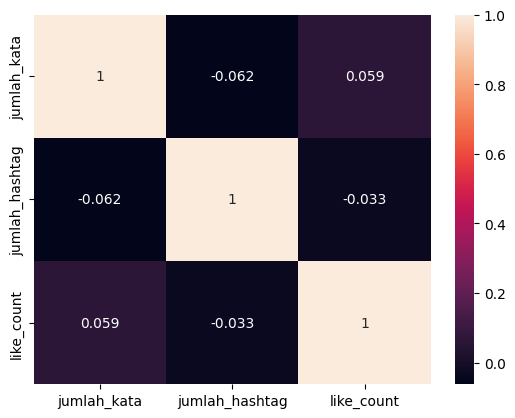

In [41]:
# Matriks korelasi
corr_matrix = data[['jumlah_kata', 'jumlah_hashtag', 'like_count']].corr()
sns.heatmap(corr_matrix, annot=True)
plt.show()

Garis Regresi

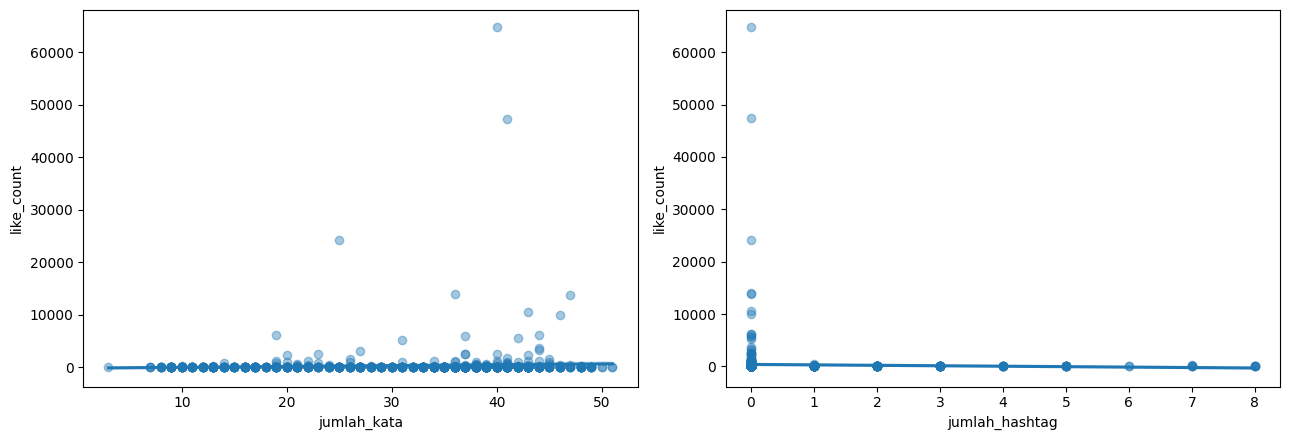

In [42]:
# Garis regresi sederhana: jumlah kata vs likes, dan jumlah hashtag vs likes
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.regplot(x='jumlah_kata', y='like_count', data=data, ax=ax[0], scatter_kws={'alpha': 0.4})
sns.regplot(x='jumlah_hashtag', y='like_count', data=data, ax=ax[1], scatter_kws={'alpha': 0.4})
plt.tight_layout()
plt.show()

Training dan Testing (80:20)

In [43]:
X = data[['jumlah_kata', 'jumlah_hashtag']]
y = data[['like_count']]

print(X.shape, y.shape)

(829, 2) (829, 1)


In [44]:
X = np.array(X)
y = np.array(y)

# split the data into test and train sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)

Data latih: (663, 2) | Data uji: (166, 2)


In [45]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression(fit_intercept=True)   # fit_intercept adalah parameter "b" (y = b + m1*x1 + m2*x2)
lr.fit(X_train, y_train)

LinearRegression()

In [46]:
print('Koefisien jumlah_kata    (m1):', lr.coef_[0][0].round(2))
print('Koefisien jumlah_hashtag (m2):', lr.coef_[0][1].round(2))
print('Intercept (b)                :', lr.intercept_[0].round(2))

Koefisien jumlah_kata    (m1): 11.34
Koefisien jumlah_hashtag (m2): -60.47
Intercept (b)                : -47.94


Evaluasi Performa Model

In [47]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = lr.predict(X_test)

y_test_1d = y_test.ravel()
y_pred_1d = y_pred.ravel()
y_train_1d = y_train.ravel()

mae = mean_absolute_error(y_test_1d, y_pred_1d)
r2 = r2_score(y_test_1d, y_pred_1d)
mae_rata2 = mean_absolute_error(y_test_1d, np.full(len(y_test_1d), y_train_1d.mean()))
mae_median = mean_absolute_error(y_test_1d, np.full(len(y_test_1d), np.median(y_train_1d)))
n_negatif = int((y_pred_1d < 0).sum())

print('MAE model                           :', round(mae, 1), 'likes')
print('R2 model                            :', round(r2, 3))
print('MAE jika selalu menebak rata-rata   :', round(mae_rata2, 1))
print('MAE jika selalu menebak median      :', round(mae_median, 1))
print('Prediksi negatif pada data uji      :', n_negatif, 'dari', len(y_pred_1d))

MAE model                           : 787.7 likes
R2 model                            : 0.001
MAE jika selalu menebak rata-rata   : 777.8
MAE jika selalu menebak median      : 577.8
Prediksi negatif pada data uji      : 3 dari 166


In [48]:
hasil = pd.DataFrame({
    'jumlah_kata': X_test[:, 0],
    'jumlah_hashtag': X_test[:, 1],
    'likes_aktual': y_test_1d,
    'likes_prediksi': y_pred_1d.round(1),
})
hasil.sort_values('likes_aktual', ascending=False).head(10)

,jumlah_kata,jumlah_hashtag,likes_aktual,likes_prediksi
106,41,0,47371,417.1
97,36,0,14028,360.4
53,43,0,10534,439.8
24,42,0,5569,428.4
103,44,0,3266,451.1
82,23,0,2618,212.9
4,40,0,2465,405.7
115,41,0,1825,417.1
139,26,0,1671,247.0
6,40,0,898,405.7


 Grafik likes aktual dibandingkan hasil prediksi

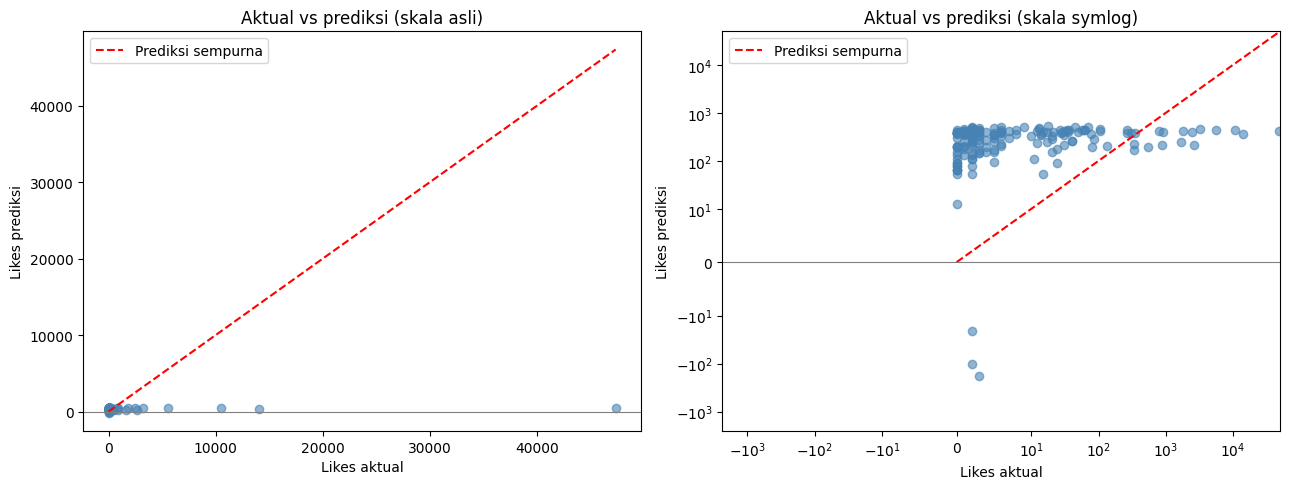

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for a, skala in zip(ax, ['linear', 'symlog']):
    a.scatter(y_test_1d, y_pred_1d, alpha=0.6, color='steelblue')
    batas = max(y_test_1d.max(), y_pred_1d.max())
    a.plot([0, batas], [0, batas], 'r--', label='Prediksi sempurna')
    a.axhline(0, color='gray', lw=0.8)
    if skala == 'symlog':
        a.set_xscale('symlog', linthresh=10)
        a.set_yscale('symlog', linthresh=10)
    a.set_xlabel('Likes aktual')
    a.set_ylabel('Likes prediksi')
    a.set_title('Aktual vs prediksi (' + ('skala asli' if skala == 'linear' else 'skala symlog') + ')')
    a.legend()

plt.tight_layout()
plt.show()

Testing Prediksi

In [50]:
new_value = [[30, 1]]
new_prediction = lr.predict(new_value)
new_prediction

array([[231.8499982]])

Save Model

In [51]:
import joblib

model_file = open('model_regresi_likes.pkl', 'wb')
joblib.dump(lr, model_file)
model_file.close()

# Dataset ringkas untuk aplikasi (tanpa kolom identitas)
data.to_csv('data_regresi.csv', index=False, encoding='utf-8')
n_dikeluarkan = len(raw) - len(data) if 'raw' in locals() else 0
pd.DataFrame([{
    'jumlah_data_dipakai': len(data),
    'jumlah_data_dikeluarkan': n_dikeluarkan,
    'data_latih': len(X_train),
    'data_uji': len(X_test),
    'random_state': 42,
    'MAE': round(mae, 2),
    'R2': round(r2, 4),
    'MAE_tebakan_rata_rata': round(mae_rata2, 2),
    'MAE_tebakan_median': round(mae_median, 2),
    'prediksi_negatif': n_negatif,
}]).to_csv('ringkasan_regresi.csv', index=False)

In [52]:
from google.colab import files
files.download('model_regresi_likes.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Analisis Sentimen Postingan X (Twitter) - Kasus KRL (Penanggung Jawab: Alvito)
Pada tahap ini dilakukan klasifikasi sentimen (**Positif**, **Netral**, atau **Negatif**) terhadap respons publik terkait dinamika KRL di Stasiun Bekasi Timur:
1. Memuat dataset bersih hasil clustering (`hasil_clustering_krl_clean_1000.csv`).
2. Menilai polaritas kata menggunakan leksikon bahasa Indonesia dengan proteksi aturan kata negasi (*tidak, belum, jangan, gak*).
3. Menganalisis sebaran sentimen secara umum dan sebaran sentimen **per tema cluster**.
4. Mengekspor dataset final yang sudah terlabeli cluster dan sentimen.

In [53]:
import os
import re
import pandas as pd
import numpy as np

# 1. Load Data Mandiri (Anti-Ngebug jika runtime ter-restart)
nama_file_cluster = 'hasil_clustering_krl_clean_1000.csv'

if not os.path.exists(nama_file_cluster):
    print("File dataset belum ditemukan di runtime. Silakan upload file hasil clustering:")
    from google.colab import files
    uploaded = files.upload()
    for fn in uploaded.keys():
        if fn.endswith('.csv'):
            nama_file_cluster = fn
            break

df_sentimen = pd.read_csv(nama_file_cluster, encoding='utf-8-sig')
print(f"Data berhasil dimuat: {len(df_sentimen)} baris postingan.")

# 2. Kamus Leksikon Sentimen Bahasa Indonesia (Disesuaikan dengan konteks KRL/transportasi)
KATA_POSITIF = {
    'apresiasi', 'sigap', 'cepat', 'aman', 'terima', 'kasih', 'hebat', 'selamat',
    'salut', 'doa', 'santunan', 'tertib', 'peduli', 'bantu', 'penghargaan', 'solidaritas',
    'pulih', 'beres', 'patut', 'cinta', 'semangat', 'bagus', 'terbaik', 'ikhlas',
    'mulia', 'damai', 'apresiasi', 'tanggap', 'pahlawan', 'berkah', 'lancar', 'syahadah'
}

KATA_NEGATIF = {
    'mogok', 'duka', 'meninggal', 'tewas', 'korban', 'terhimpit', 'hancur', 'rusak',
    'lambat', 'telat', 'kecewa', 'kelalaian', 'kacau', 'bajingan', 'luka', 'tabrakan',
    'horor', 'nangis', 'tangis', 'mati', 'parah', 'kritis', 'ancur', 'biang', 'kerok',
    'lalai', 'bahaya', 'maut', 'pilu', 'nyawa', 'hilang', 'tangisan', 'marah', 'buruk',
    'masalah', 'gangguan', 'tertahan', 'antre', 'menumpuk', 'sesak', 'keluh', 'sengsara'
}

NEGASI = {'tidak', 'bukan', 'belum', 'jangan', 'tanpa', 'gak', 'ga', 'ngga', 'engga', 'nggak', 'tak'}

# 3. Fungsi Penghitungan Skor Sentimen Berbasis Aturan (Rule-Based dengan Negasi)
def hitung_sentimen(teks):
    kata_list = str(teks).lower().split()
    skor = 0
    negasi_aktif = False

    for i, kata in enumerate(kata_list):
        if kata in NEGASI:
            negasi_aktif = True
            continue

        bobot = 0
        if kata in KATA_POSITIF:
            bobot = 1
        elif kata in KATA_NEGATIF:
            bobot = -1

        if bobot != 0:
            if negasi_aktif:
                bobot = -bobot  # Balikkan makna jika didahului kata negasi (cth: "tidak aman" -> negatif)
                negasi_aktif = False
            skor += bobot
        else:
            negasi_aktif = False

    if skor > 0:
        return skor, 'Positif'
    elif skor < 0:
        return skor, 'Negatif'
    else:
        return 0, 'Netral'

# Terapkan pada data
hasil_sentimen = df_sentimen['clean_text'].apply(hitung_sentimen)
df_sentimen['skor_sentimen'] = [h[0] for h in hasil_sentimen]
df_sentimen['sentimen'] = [h[1] for h in hasil_sentimen]

# Tampilkan ringkasan
print("\n=== DISTRIBUSI SENTIMEN KESELURUHAN ===")
distribusi_sentimen = df_sentimen['sentimen'].value_counts()
for s, j in distribusi_sentimen.items():
    print(f"- Sentimen {s:<7}: {j:>4} tweet ({j/len(df_sentimen)*100:.2f}%)")

df_sentimen[['clean_text', 'cluster', 'tema_cluster', 'sentimen', 'skor_sentimen']].head(5)

Data berhasil dimuat: 829 baris postingan.

=== DISTRIBUSI SENTIMEN KESELURUHAN ===
- Sentimen Negatif:  396 tweet (47.77%)
- Sentimen Netral :  390 tweet (47.04%)
- Sentimen Positif:   43 tweet (5.19%)


,clean_text,cluster,tema_cluster,sentimen,skor_sentimen
0,relawan pmi mendapat apresiasi langsung dari j...,0,Respons Kebijakan & Informasi Operasional KRL,Positif,3
1,mau tidur nangis bangun tidur nangis tiap liat...,0,Respons Kebijakan & Informasi Operasional KRL,Netral,0
2,hari yang lalu ada buruh perempuan yg gugur di...,0,Respons Kebijakan & Informasi Operasional KRL,Negatif,-1
3,duka di stasiun bekasi timur korban kecelakaan...,1,"Keterlambatan, Gangguan Jalur & Keluhan Penumpang",Negatif,-1
4,sebanyak relawan pmi mendapat bonus usai memba...,0,Respons Kebijakan & Informasi Operasional KRL,Positif,2


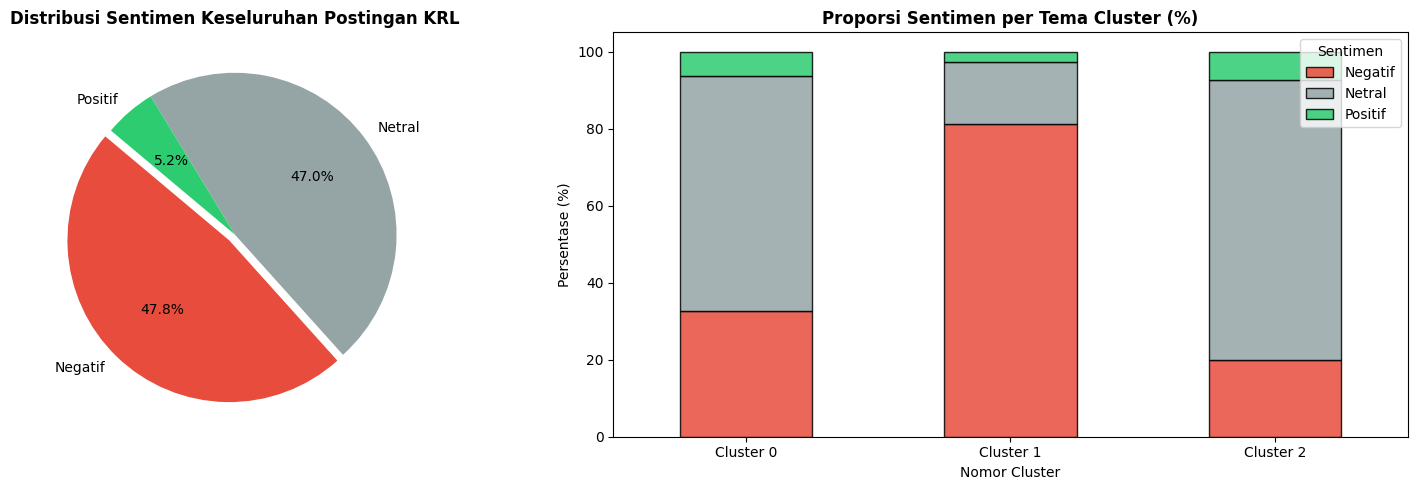

sentimen,Negatif,Netral,Positif,Total
tema_cluster,,,,
"Insiden, Evakuasi & Dampak Perjalanan Stasiun",11,40,4,55
"Keterlambatan, Gangguan Jalur & Keluhan Penumpang",221,44,7,272
Respons Kebijakan & Informasi Operasional KRL,164,306,32,502
Total,396,390,43,829


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
warna_sentimen = {'Negatif': '#e74c3c', 'Netral': '#95a5a6', 'Positif': '#2ecc71'}

# 1. Pie Chart Distribusi Sentimen Total
dist_all = df_sentimen['sentimen'].value_counts()
axes[0].pie(
    dist_all,
    labels=dist_all.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=[warna_sentimen[k] for k in dist_all.index],
    explode=[0.05 if k == 'Negatif' else 0 for k in dist_all.index]
)
axes[0].set_title('Distribusi Sentimen Keseluruhan Postingan KRL', fontsize=12, fontweight='bold')

# 2. Bar Chart Sebaran Sentimen per Tema Cluster (Menghubungkan Clustering & Sentimen)
ct = pd.crosstab(df_sentimen['cluster'], df_sentimen['sentimen'], normalize='index') * 100
kolom_order = [k for k in ['Negatif', 'Netral', 'Positif'] if k in ct.columns]
ct = ct[kolom_order]

ct.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    color=[warna_sentimen[k] for k in kolom_order],
    edgecolor='black',
    alpha=0.85
)
axes[1].set_title('Proporsi Sentimen per Tema Cluster (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nomor Cluster')
axes[1].set_ylabel('Persentase (%)')
axes[1].legend(title='Sentimen', loc='upper right')
axes[1].set_xticklabels([f"Cluster {i}" for i in ct.index], rotation=0)

plt.tight_layout()
plt.show()

# Tabel silang detail sentimen per cluster
tabel_cluster_sentimen = pd.crosstab(
    df_sentimen['tema_cluster'],
    df_sentimen['sentimen'],
    margins=True,
    margins_name="Total"
)
display(tabel_cluster_sentimen)

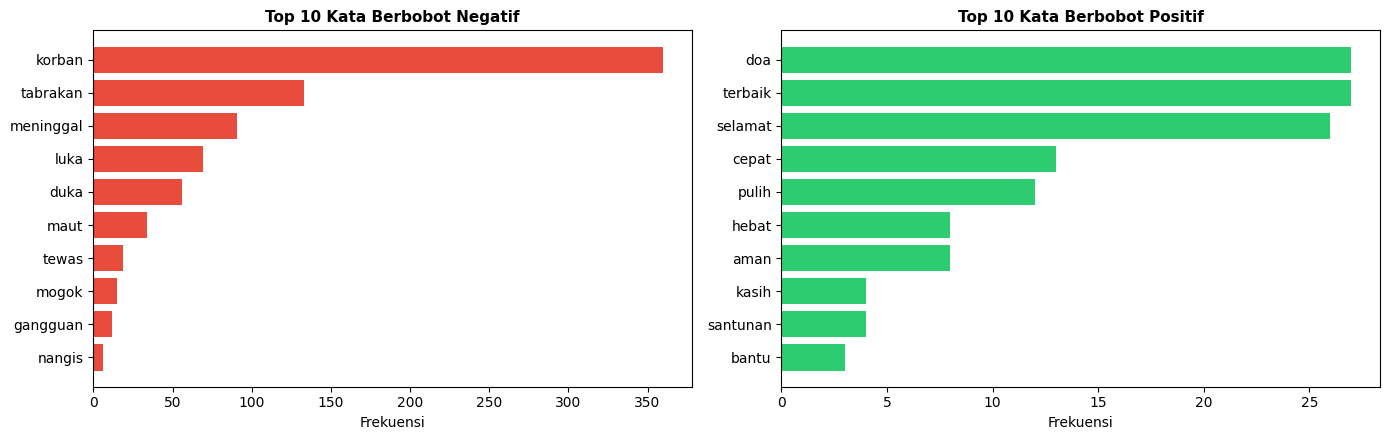

In [55]:
from collections import Counter

semua_kata = ' '.join(df_sentimen['clean_text']).split()
kata_pos_terhitung = Counter([k for k in semua_kata if k in KATA_POSITIF]).most_common(10)
kata_neg_terhitung = Counter([k for k in semua_kata if k in KATA_NEGATIF]).most_common(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot Top Kata Negatif
if kata_neg_terhitung:
    k_neg, c_neg = zip(*kata_neg_terhitung)
    ax[0].barh(k_neg[::-1], c_neg[::-1], color='#e74c3c')
    ax[0].set_title('Top 10 Kata Berbobot Negatif', fontsize=11, fontweight='bold')
    ax[0].set_xlabel('Frekuensi')

# Plot Top Kata Positif
if kata_pos_terhitung:
    k_pos, c_pos = zip(*kata_pos_terhitung)
    ax[1].barh(k_pos[::-1], c_pos[::-1], color='#2ecc71')
    ax[1].set_title('Top 10 Kata Berbobot Positif', fontsize=11, fontweight='bold')
    ax[1].set_xlabel('Frekuensi')

plt.tight_layout()
plt.show()

In [56]:
import csv

file_final_sentimen = 'hasil_analisis_sentimen_krl.csv'

# Ekspor dataset komplit dengan proteksi Excel
df_sentimen.to_csv(
    file_final_sentimen,
    index=False,
    encoding='utf-8-sig',
    quoting=csv.QUOTE_ALL,
    lineterminator='\r\n'
)

print(f"Dataset final berhasil disimpan ke '{file_final_sentimen}'!")
print(f"Total baris: {len(df_sentimen)}")

# Unduh otomatis jika di Google Colab
try:
    from google.colab import files
    files.download(file_final_sentimen)
    print("Memicu unduhan otomatis...")
except Exception:
    pass

Dataset final berhasil disimpan ke 'hasil_analisis_sentimen_krl.csv'!
Total baris: 829


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Memicu unduhan otomatis...
